# Thí nghiệm 3 – Random Forest dự đoán xu hướng tiến độ

**Câu hỏi:** từ dữ liệu tập luyện đến hết tuần này, có dự đoán được tuần sau người dùng có bám kế hoạch và tập nặng đến đâu không, và Random Forest (RF) có tốt hơn các cách đơn giản (baseline) không?

| Bài toán | Biến mục tiêu | Chỉ số chính |
|---|---|---|
| Phân loại | `on_plan_next` = tuần sau hoàn thành **≥ 80%** số buổi trong lịch | F1 (lớp "đạt"), kèm accuracy, ROC-AUC |
| Hồi quy | `volume_next` = tổng khối lượng tuần sau (kg) | MAE (kg) và MAE / trung bình (%) |

**Dữ liệu:** `ml/data/synthetic_weeks.csv` (mô phỏng, `python ml/generate_synthetic.py`) và nếu có thì `ml/data/real_weeks.csv` (xuất từ ứng dụng, `pnpm ml:export`, chỉ người dùng đồng ý cho nghiên cứu, mã người dùng đã ẩn danh). Mỗi dòng là một người dùng trong một tuần (thứ Hai – Chủ nhật).

**Chạy lại:** `python -m jupyter nbconvert --to notebook --execute --inplace ml/progress_rf.ipynb` (xem `docs/experiments.md`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, mean_absolute_error

sys.path.insert(0, str(Path.cwd()))
import progress_lib as P

FIG = Path.cwd() / "figures"
FIG.mkdir(exist_ok=True)
ACCENT, NEUTRAL, INK, MUTED = "#ff5a1f", "#a3a3a3", "#1c1c1c", "#6b6b6b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8,
                     "axes.axisbelow": True, "axes.edgecolor": "#cccccc", "text.color": INK,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED})

weeks = P.load_weeks()
weeks.groupby("is_synthetic").agg(nguoi_dung=("user_id", "nunique"), dong_user_tuan=("user_id", "size"),
                                  tu=("week_start", "min"), den=("week_start", "max"))

,nguoi_dung,dong_user_tuan,tu,den
is_synthetic,,,,
1,300,5822,2025-11-03,2026-09-07


## 1. Đặc trưng và biến mục tiêu

Đặc trưng của tuần *t* chỉ dùng dữ liệu của tuần *t* và các tuần trước (không nhìn trước tương lai):

- **Tuân thủ:** tỉ lệ hoàn thành tuần này, tuần trước, trung bình và độ lệch chuẩn 3 tuần gần nhất.
- **Tải tập:** số buổi, số set, khối lượng tuần này / tuần trước / trung bình 3 tuần, % thay đổi khối lượng.
- **Cảm nhận:** RPE trung bình tuần này và tuần trước.
- **Cơ thể:** thay đổi cân nặng 2 tuần, số rep Squat đếm bằng camera.
- **Hồ sơ:** mục tiêu, trình độ, giới tính, nhóm tuổi, số buổi đặt ra mỗi tuần, số tuần đã dùng app.

Tuần đầu tiên của mỗi người (chưa có lịch sử) và tuần cuối (chưa có "tuần sau") bị loại.

In [2]:
feat = P.build_features(weeks)
print(f"{len(feat):,} mẫu, {feat['user_id'].nunique()} người dùng, {len(P.NUMERIC)} đặc trưng số + {len(P.CATEGORICAL)} đặc trưng phân loại")
pd.DataFrame({
    "tỉ lệ tuần sau đạt ≥ 80%": [feat["on_plan_next"].mean()],
    "khối lượng tuần sau – trung bình (kg)": [feat["volume_next"].mean()],
    "khối lượng tuần sau – trung vị (kg)": [feat["volume_next"].median()],
}).round(3)

5,222 mẫu, 300 người dùng, 18 đặc trưng số + 3 đặc trưng phân loại


,tỉ lệ tuần sau đạt ≥ 80%,khối lượng tuần sau – trung bình (kg),khối lượng tuần sau – trung vị (kg)
0,0.321,2982.115,1814.85


## 2. Phương pháp đánh giá

- **TimeSeriesSplit 5 fold theo tuần lịch:** mỗi fold huấn luyện trên các tuần trước và kiểm tra trên các tuần sau đó; một tuần không bao giờ vừa nằm ở tập huấn luyện vừa ở tập kiểm tra. Cách chia này mô phỏng việc dùng mô hình thật: chỉ biết quá khứ.
- Giá trị thiếu (ví dụ RPE khi tuần không tập) được điền bằng trung vị **của tập huấn luyện từng fold**.
- **Baseline phân loại:** (a) "tuần này đã ≥ 80% thì tuần sau cũng vậy"; (b) "trung bình 3 tuần ≥ 80%"; (c) Logistic Regression.
- **Baseline hồi quy:** (a) "tuần sau bằng tuần này"; (b) trung bình trượt 3 tuần; (c) Linear Regression.
- **Random Forest:** 300 cây, `min_samples_leaf=5`, `class_weight="balanced"` cho phân loại, `random_state=42`. Không tinh chỉnh siêu tham số để so sánh công bằng với baseline.

In [3]:
cls = P.evaluate(feat, "classification")
P.summarize(cls, ["f1", "accuracy", "roc_auc"])

f1        accuracy        roc_auc       
                          mean    std     mean    std    mean    std
model                                                               
Tuần này ≥ 80%           0.455  0.044    0.642  0.032   0.603  0.042
Trung bình 3 tuần ≥ 80%  0.397  0.033    0.677  0.025   0.668  0.016
Logistic Regression      0.540  0.023    0.652  0.024   0.699  0.021
Random Forest            0.536  0.059    0.710  0.016   0.716  0.018

In [4]:
reg = P.evaluate(feat, "regression")
P.summarize(reg, ["mae", "mae_pct_of_mean"])

mae          mae_pct_of_mean       
                         mean      std            mean    std
model                                                        
Giữ nguyên tuần này  1413.436  157.978          45.751  2.101
Trung bình 3 tuần    1139.101  101.384          36.964  2.404
Linear Regression    1086.208   64.951          35.401  3.568
Random Forest        1109.232   96.923          36.036  2.962

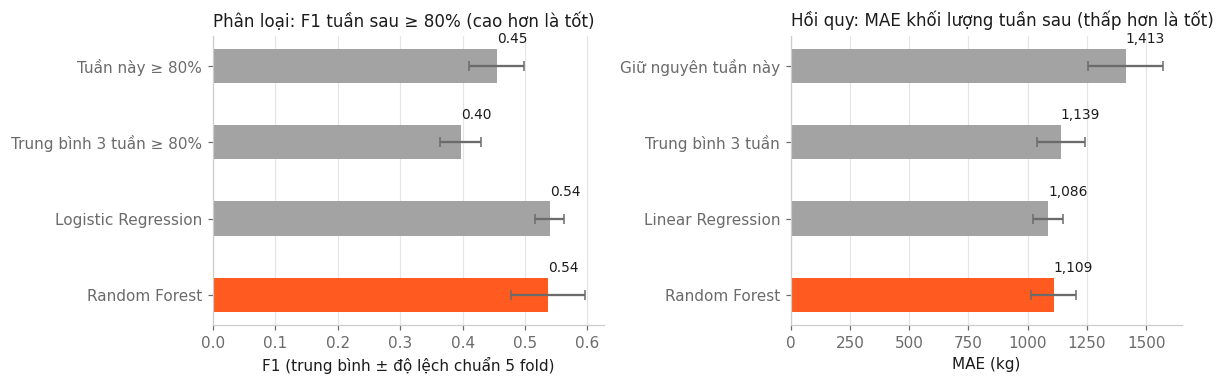

In [5]:
def bars(ax, results, metric, title, xlabel):
    s = results.groupby("model", sort=False)[metric].agg(["mean", "std"])
    colors = [ACCENT if m == "Random Forest" else NEUTRAL for m in s.index]
    y = np.arange(len(s))[::-1]
    ax.barh(y, s["mean"], xerr=s["std"], color=colors, height=0.45, error_kw={"ecolor": MUTED, "capsize": 3})
    ax.set_yticks(y, s.index)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    for yi, v in zip(y, s["mean"]):
        ax.text(v, yi + 0.3, f"{v:,.2f}" if v < 10 else f"{v:,.0f}", fontsize=9, color=INK)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
bars(axes[0], cls, "f1", "Phân loại: F1 tuần sau ≥ 80% (cao hơn là tốt)", "F1 (trung bình ± độ lệch chuẩn 5 fold)")
bars(axes[1], reg, "mae", "Hồi quy: MAE khối lượng tuần sau (thấp hơn là tốt)", "MAE (kg)")
fig.tight_layout()
fig.savefig(FIG / "model_comparison.png", bbox_inches="tight")

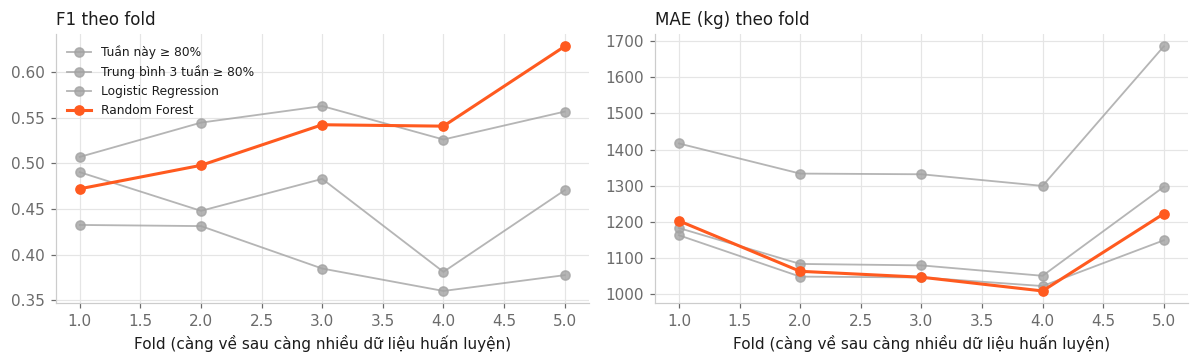

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
for ax, (res, metric, title) in zip(axes, [(cls, "f1", "F1 theo fold"), (reg, "mae", "MAE (kg) theo fold")]):
    for name, part in res.groupby("model", sort=False):
        rf = name == "Random Forest"
        ax.plot(part["fold"], part[metric], marker="o", lw=2 if rf else 1.2,
                color=ACCENT if rf else NEUTRAL, alpha=1 if rf else 0.8, label=name)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("Fold (càng về sau càng nhiều dữ liệu huấn luyện)")
axes[0].legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIG / "metrics_by_fold.png", bbox_inches="tight")

## 3. Đặc trưng nào quan trọng?

Dùng **permutation importance** trên 20% tuần cuối (mô hình huấn luyện trên 80% tuần đầu): xáo trộn một đặc trưng rồi đo chỉ số giảm bao nhiêu. Cách này đáng tin hơn impurity importance của cây vì không thiên vị đặc trưng có nhiều giá trị.

,phân loại,hồi quy
0,volume_lag1,volume_ma3
1,volume_ma3,volume_lag1
2,avg_rpe,level_beginner
3,sex_male,completion_ma3
4,level_beginner,avg_rpe


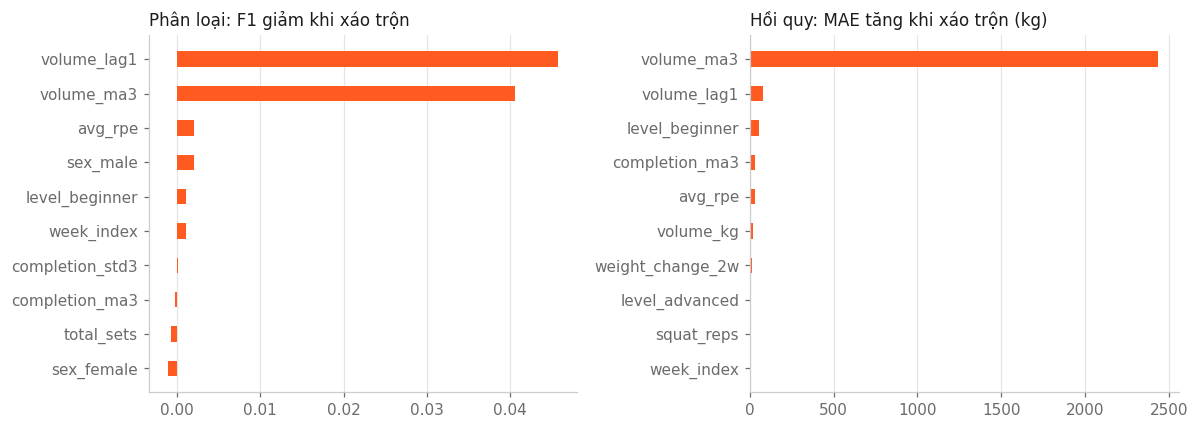

In [7]:
def importance(task, scoring, title, ax):
    model, x_test, y_test = P.fit_full_forest(feat, task)
    r = permutation_importance(model, x_test, y_test, scoring=scoring, n_repeats=10, random_state=P.SEED)
    imp = pd.Series(r.importances_mean, index=x_test.columns).sort_values().tail(10)
    ax.barh(imp.index, imp.values, color=ACCENT, height=0.45)
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="y", visible=False)
    return imp[::-1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
imp_cls = importance("classification", "f1", "Phân loại: F1 giảm khi xáo trộn", axes[0])
imp_reg = importance("regression", "neg_mean_absolute_error", "Hồi quy: MAE tăng khi xáo trộn (kg)", axes[1])
fig.tight_layout()
fig.savefig(FIG / "feature_importance.png", bbox_inches="tight")
pd.DataFrame({"phân loại": imp_cls.index[:5], "hồi quy": imp_reg.index[:5]})

## 4. Tóm tắt kết quả (sinh tự động từ số liệu ở trên)

In [8]:
def best_baseline(res, metric, higher):
    s = res[res["model"] != "Random Forest"].groupby("model")[metric].mean()
    return (s.idxmax(), s.max()) if higher else (s.idxmin(), s.min())

rf_f1 = cls[cls["model"] == "Random Forest"]["f1"].mean()
b_name, b_f1 = best_baseline(cls, "f1", True)
rf_mae = reg[reg["model"] == "Random Forest"]["mae"].mean()
r_name, r_mae = best_baseline(reg, "mae", False)
synthetic_share = weeks["is_synthetic"].mean()
rf_f1_std = cls[cls["model"] == "Random Forest"]["f1"].std()
rf_mae_std = reg[reg["model"] == "Random Forest"]["mae"].std()

def verdict(diff, spread, better_if_positive):
    if abs(diff) < spread:
        return "tương đương (chênh lệch nhỏ hơn độ lệch chuẩn giữa các fold)"
    good = diff > 0 if better_if_positive else diff < 0
    return "RF tốt hơn" if good else "RF kém hơn"

print(f"Dữ liệu: {synthetic_share:.1%} số dòng là MÔ PHỎNG ({(~weeks['is_synthetic'].astype(bool)).sum()} dòng thật).")
print(f"Phân loại: RF F1 = {rf_f1:.3f} ± {rf_f1_std:.3f}; baseline tốt nhất ({b_name}) F1 = {b_f1:.3f} "
      f"-> chênh {rf_f1 - b_f1:+.3f}: {verdict(rf_f1 - b_f1, rf_f1_std, True)}.")
print(f"Hồi quy:   RF MAE = {rf_mae:,.0f} ± {rf_mae_std:,.0f} kg; baseline tốt nhất ({r_name}) MAE = {r_mae:,.0f} kg "
      f"-> chênh {rf_mae - r_mae:+,.0f} kg: {verdict(rf_mae - r_mae, rf_mae_std, False)}.")

Dữ liệu: 100.0% số dòng là MÔ PHỎNG (0 dòng thật).
Phân loại: RF F1 = 0.536 ± 0.059; baseline tốt nhất (Logistic Regression) F1 = 0.540 -> chênh -0.003: tương đương (chênh lệch nhỏ hơn độ lệch chuẩn giữa các fold).
Hồi quy:   RF MAE = 1,109 ± 97 kg; baseline tốt nhất (Linear Regression) MAE = 1,086 kg -> chênh +23 kg: tương đương (chênh lệch nhỏ hơn độ lệch chuẩn giữa các fold).


## 5. Hạn chế (cần ghi trong báo cáo)

1. **Dữ liệu chủ yếu là mô phỏng.** Các quy luật trong `generate_synthetic.py` (tuân thủ nền theo trình độ, tuần bận, mệt mỏi khi tăng tải đột ngột, mục tiêu quá cao) do nhóm tự đặt ra; mô hình học lại đúng các giả định đó. Kết quả trên dữ liệu mô phỏng chỉ chứng minh **pipeline chạy đúng**, không chứng minh RF dự đoán được người thật.
2. **Dữ liệu thật rất ít** ở thời điểm chạy (vài người dùng thử nghiệm, vài tuần). Cần thu thập thêm (người dùng đồng ý nghiên cứu) và chạy lại notebook với `include_real=True` (mặc định), sau đó báo cáo riêng kết quả trên phần dữ liệu thật.
3. **Nhiều người dùng chung một mốc thời gian:** TimeSeriesSplit theo tuần lịch tránh rò rỉ thời gian, nhưng các tuần của cùng một người vẫn xuất hiện ở cả train và test (mô hình "biết" người đó). Nếu muốn đánh giá trên người dùng mới hoàn toàn, dùng thêm GroupKFold theo `user_id`.
4. **Ngưỡng 80%** là lựa chọn của nhóm (trùng mục tiêu trên Dashboard); đổi ngưỡng sẽ đổi tỉ lệ lớp và F1.
5. **Khối lượng tuần** = tổng tạ × rep, không tính bài không tạ (bodyweight có tạ = 0), nên bài toán hồi quy thiên về người tập tạ.
6. Không tinh chỉnh siêu tham số và không lặp nhiều seed; nếu báo cáo chênh lệch nhỏ, nên chạy thêm nhiều seed hoặc kiểm định thống kê (ví dụ Wilcoxon trên các fold).